# 9장 실습. 온프레미스 대안: Laya·RLCD·AnyJev

Jev 는 SaaS API 다. 판단하려면 state 원문이 밖으로 나간다. 데이터를 내보낼 수 없는 곳에서는 같은 일을 사내에서 하는 엔진이 필요하다. 이 노트북은 사내 GPU 에서 도는 대안 둘을 직접 돌리고, 같은 로컬 LLM 을 「생성기」로 쓸 때와도 견준다.

| 갈래 | 이 노트북의 엔진 | 새로 학습 | 무엇을 읽나 |
|---|---|---|---|
| 전용 경량 인코더 | Laya (`laya.Router`, 한국어는 mmBERT-base) | 과제별 파인튜닝(4부) | 선택지마다 붙은 결정 헤드의 로짓 |
| 생성 모델 개조 + RLCD | (이 책에서는 개념만 다룬다) | 보정 학습 | — |
| 학습 없는 로짓 읽기 | AnyJev 방식 (로컬 LLM 의 첫 토큰 확률) | 없음 | 선택지 기호의 확률 |
| 비교: 생성기로 쓰기 | 로컬 LLM 에 글로 묻기 | 없음 | 답과 스스로 적은 확신 |

| 절 | 내용 |
|---|---|
| 9.1 | 같은 러닝 예제를 네 엔진에 묻는다 |
| 9.2 | 선택지 순서를 돌리면 답이 바뀌는가 — 위치 편향과 순환 순열 |
| 9.3 | 지연·비용·밖으로 나가는 데이터 |

Laya multilingual 체크포인트(약 1.3GB)와 로컬 LLM 을 함께 올린다. Laya 가 작아서 한 GPU 에 같이 들어간다. Jev 에는 몇 건만 보낸다.

In [1]:
import os, json, time, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import koreanize_matplotlib  # noqa: F401
from dotenv import load_dotenv
from requests.adapters import HTTPAdapter, Retry

load_dotenv()
DATA, OUT = Path("data"), Path("out")
OUT.mkdir(exist_ok=True)
TASKS = ["topic", "entails", "positive", "similarity"]
COLOR = {"topic": "#2a78d6", "entails": "#eb6834", "positive": "#1baf7a", "similarity": "#eda100"}
pd.set_option("display.precision", 3)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
read_jsonl = lambda p: [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]

assert (DATA / "eval_v1.jsonl").exists(), "평가셋이 없다. nb00_setup → nb08_evaluation 을 먼저 실행한다"

JEV_URL = os.getenv("JEV_URL", "https://api.typesafe.ai")
http = requests.Session()
http.mount(JEV_URL, HTTPAdapter(max_retries=Retry(total=4, backoff_factor=0.5, status_forcelist=[408, 429, 500, 502, 503, 504])))

def ask(state, questions, model="jev-latest"):
    r = http.post(f"{JEV_URL}/v1/systemone", timeout=60, headers={"Authorization": f"Bearer {os.environ['TYPESAFE_API_KEY']}"},
                  json={"model": model, "state": state, "questions": questions})
    r.raise_for_status()
    return r.json() | {"_latency_s": r.elapsed.total_seconds()}

choice = lambda instructions, criteria: {"type": "choice", "instructions": instructions, "criteria": criteria}
score = lambda instructions, levels: {"type": "score", "instructions": instructions, "criteria": levels}
noul = lambda instructions, true="", false="": {"type": "noul", "instructions": instructions} | ({"criteria": {"true": true, "false": false}} if true else {})

import laya
from laya import Router

router = Router()                          # 한국어는 multilingual 체크포인트로 간다(10장)

def laya_post(state, questions):
    t0 = time.perf_counter()
    r = router.predict(state, questions)
    return r | {"model": "laya:" + r["routing"]["model"], "usage": {"input_tokens": 0}, "_latency_s": time.perf_counter() - t0}
print("laya", laya.__version__)

laya 0.4.7


In [2]:
from transformers import AutoModelForCausalLM, AutoTokenizer

LLM_MODEL = os.environ["LOCAL_LLM_MODEL"]
tok = AutoTokenizer.from_pretrained(LLM_MODEL, padding_side="left")
tok.pad_token = tok.pad_token or tok.eos_token
lm = AutoModelForCausalLM.from_pretrained(LLM_MODEL, dtype="auto", device_map="auto")

def chat_batch(prompts, max_new_tokens=256, batch_size=16, system=None):
    # 프롬프트 여럿을 묶어 generate 한 번에 보낸다(왼쪽 패딩). 서빙 엔진 없이 처리량을 내는 방법이다
    msgs = lambda p: [{"role": "system", "content": system}] * bool(system) + [{"role": "user", "content": p}]
    texts = [tok.apply_chat_template(msgs(p), tokenize=False, add_generation_prompt=True, enable_thinking=False) for p in prompts]
    outs = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], return_tensors="pt", padding=True).to(lm.device)
        gen = lm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
        outs += tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

chat = lambda prompt, **kw: chat_batch([prompt], **kw)[0]
print(LLM_MODEL, "|", lm.device)

import torch

LETTERS = "ABCDEFGHIJ"
letter_ids = [tok.encode(c, add_special_tokens=False)[0] for c in LETTERS]
OPTIONS = {"choice": lambda c: [(k, f"{k}: {v}") for k, v in c.items()],
           "score": lambda c: [(str(i), lv) for i, lv in enumerate(c)],
           "noul": lambda c: [("true", f"참. {c.get('true', '')}"), ("false", f"거짓. {c.get('false', '')}")]}

def anyjev_prompt(state, q, texts, order):
    menu = "\n".join(f"{LETTERS[s]}. {texts[j]}" for s, j in enumerate(order))
    user = f"[판단할 대상]\n{json.dumps(state, ensure_ascii=False)}\n\n[질문]\n{q['instructions']}\n{menu}\n\n답(기호 한 글자):"
    msgs = [{"role": "system", "content": "너는 판단만 하는 분류기다. 질문을 읽고 선택지 기호 한 글자로만 답한다."}, {"role": "user", "content": user}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)

def rotations(state, q, cyclic=True):
    # 선택지 순서를 한 칸씩 돌린 k 개 프롬프트를 한 배치로 보내고, 첫 토큰에서 기호들의 로그 확률을 읽는다
    keys, texts = zip(*OPTIONS[q["type"]](q.get("criteria") or {}))
    k = len(keys)
    orders = np.array([[(i + s) % k for i in range(k)] for s in range(k if cyclic else 1)])
    enc = tok([anyjev_prompt(state, q, texts, o) for o in orders], return_tensors="pt", padding=True).to(lm.device)
    with torch.no_grad():
        logits = lm(**enc).logits[:, -1].float()
    slot = torch.log_softmax(logits, -1)[:, letter_ids[:k]].cpu().numpy()       # [회전, 자리]
    R = np.zeros_like(slot)
    np.put_along_axis(R, orders, slot, axis=1)                                  # 자리 → 원래 선택지 순서
    return list(keys), R, int(enc["attention_mask"].sum())

ANSWER = {"noul": lambda keys, p: {"type": "noul", "noul": float(p[keys.index("true")])},
          "choice": lambda keys, p: {"type": "choice", "choice": keys[int(p.argmax())], "probabilities": dict(zip(keys, map(float, p)))},
          "score": lambda keys, p: {"type": "score", "score": float(np.dot(np.arange(len(p)), p)), "probabilities": dict(zip(keys, map(float, p)))}}

def anyjev(state, questions):
    t0, answers, tokens = time.perf_counter(), {}, 0
    for name, q in questions.items():
        keys, R, n = rotations(state, q)
        p = np.exp(R.mean(0) - R.mean(0).max())                                 # 회전 평균 로그 확률 → 확률
        answers[name], tokens = ANSWER[q["type"]](keys, p / p.sum()), tokens + n
    return {"model": "anyjev:" + LLM_MODEL, "answers": answers, "usage": {"input_tokens": tokens}, "_latency_s": time.perf_counter() - t0}

import re

KEYS = {"choice": lambda q: list(q["criteria"]), "score": lambda q: [str(i) for i in range(len(q["criteria"]))], "noul": lambda q: ["true", "false"]}
LINES = {"choice": lambda q: [f"  {k}: {v}" for k, v in q["criteria"].items()],
         "score": lambda q: [f"  {i}: {v}" for i, v in enumerate(q["criteria"])],
         "noul": lambda q: [f"  {k}: {v}" for k, v in (q.get("criteria") or {"true": "그렇다", "false": "아니다"}).items()]}

def gen_prompt(state, q):
    return "\n".join(["[판단할 대상]", json.dumps(state, ensure_ascii=False), "", "[질문]", q["instructions"], "[선택지]", *LINES[q["type"]](q), "",
                       "선택지 키 하나와, 그 답이 맞을 확률을 아래 두 줄 형식으로만 답하라.", "답: <선택지 키>", "확신: <0과 1 사이 숫자>"])

def gen_answer(q, text):
    keys = KEYS[q["type"]](q)
    ans = (re.findall(r"답\s*[:：]\s*(\S+)", text) + [None])[0]
    conf = float((re.findall(r"확신\s*[:：]\s*([01](?:\.\d+)?)", text) + ["nan"])[0])
    p = {k: [(1 - conf) / (len(keys) - 1), conf][k == ans] for k in keys} if ans in keys and conf == conf else {k: 1 / len(keys) for k in keys}
    return {"type": q["type"], "probabilities": p, "noul": p.get("true"), "choice": max(p, key=p.get), "invalid": ans not in keys, "raw": text}

def gen_many(states_questions, batch_size=16):
    # (state, 질문 하나짜리 dict) 목록을 묶어서 생성하고 Jev 모양의 응답으로 바꾼다
    flat = [(s, n, q) for s, qs in states_questions for n, q in qs.items()]
    t0 = time.perf_counter()
    outs = chat_batch([gen_prompt(s, q) for s, _, q in flat], max_new_tokens=24, batch_size=batch_size)
    sec = (time.perf_counter() - t0) / len(flat)
    return [{"model": "llm:" + LLM_MODEL, "answers": {n: gen_answer(q, o)}, "usage": {"input_tokens": 0}, "_latency_s": sec}
            for (s, n, q), o in zip(flat, outs)]

/home/josh/anaconda3/envs/pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Ignoring corrupted tree cache file /data/shared/hf/hub/models--Qwen--Qwen3.5-4B/trees/851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a.json: [Errno 13] Permission denied: '/data/shared/hf/hub/models--Qwen--Qwen3.5-4B/trees/851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a.json'
Loading weights: 100%|██████████| 426/426 [00:01<00:00, 377.34it/s]


Qwen/Qwen3.5-4B | cuda:0


## 9.1 엔진 비교: Laya·AnyJev·로컬 LLM·Jev

2장의 러닝 예제(결제 중복 문의, 질문 셋)를 네 엔진에 보낸다. 첫 호출에는 모델을 올리는 시간이 섞이므로 두 번 부르고 두 번째를 잰다. 로컬 LLM 은 질문마다 글로 묻는다.

In [3]:
TICKET_STATE = {"channel": "앱 문의",
                "message": "결제가 두 번 됐어요. 어제 저녁에 한 번만 결제했는데 카드 문자가 두 번 왔습니다. 오늘 안에 처리 안 되면 해지할게요."}
TICKET_QUESTIONS = {
    "department": choice("이 문의를 처리할 팀", {"billing": "결제, 환불, 청구 오류", "technical": "앱 오류, 로그인, 연동 문제",
                                             "account": "가입, 해지, 요금제 변경", "general": "그 밖의 문의"}),
    "urgency": score("얼마나 급하게 처리해야 하는가", ["일반 처리로 충분하다", "오늘 안에 처리해야 한다", "즉시 사람이 연락해야 한다"]),
    "churn_risk": noul("고객이 해지를 언급하거나 해지할 뜻을 보인다",
                       true="해지·탈퇴·이용 중단을 직접 말하거나 조건부로 예고한다", false="해지에 관한 언급이 없다"),
}

def local_llm(state, questions):
    t0 = time.perf_counter()
    outs = chat_batch([gen_prompt(state, q) for q in questions.values()], max_new_tokens=24)
    answers = {n: gen_answer(q, o) for (n, q), o in zip(questions.items(), outs)}
    return {"model": "llm:" + LLM_MODEL, "answers": answers, "usage": {"input_tokens": 0}, "_latency_s": time.perf_counter() - t0}

ENGINES = {"Laya": laya_post, "AnyJev": anyjev, "로컬 LLM (생성)": local_llm, "Jev": ask}
res = {name: [e(TICKET_STATE, TICKET_QUESTIONS) for _ in range(2)][-1] for name, e in ENGINES.items()}
score_of = lambda a: sum(int(k) * v for k, v in a["probabilities"].items())
pd.DataFrame([{"엔진": name, "모델": r["model"], "department": max(r["answers"]["department"]["probabilities"], key=r["answers"]["department"]["probabilities"].get),
               "p(department)": max(r["answers"]["department"]["probabilities"].values()), "urgency": score_of(r["answers"]["urgency"]),
               "churn_risk": r["answers"]["churn_risk"]["noul"], "입력 토큰": r["usage"]["input_tokens"], "지연(초)": r["_latency_s"]}
              for name, r in res.items()])

Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 2074.74it/s]
[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


,엔진,모델,department,p(department),urgency,churn_risk,입력 토큰,지연(초)
0,Laya,laya:multilingual,billing,0.964,1.346,0.944,0,0.016
1,AnyJev,anyjev:Qwen/Qwen3.5-4B,billing,0.999,1.439,0.998,1383,0.206
2,로컬 LLM (생성),llm:Qwen/Qwen3.5-4B,billing,0.950,1.925,0.950,0,0.705
3,Jev,jev-1.13.0,billing,1.000,1.070,0.990,565,0.221


로컬 LLM 의 확률은 모델이 「확신: 0.9」처럼 스스로 적은 숫자를 고른 답에 주고 나머지를 고르게 나눈 것이다. 보정을 목표로 학습한 값이 아니다. 같은 모델이라도 AnyJev 는 첫 토큰의 실제 확률을 읽는다. 둘이 얼마나 다른지는 12장에서 평가셋 800건으로 잰다.

## 9.2 위치 편향과 순환 순열

선택지를 나열하는 순서는 내용과 상관이 없어야 한다. 그런데 LLM 은 특정 기호를 더 자주 고르는 자리 선호가 있고, Laya 도 자리에 따라 로짓이 기운다(Laya README 의 Option order 절). 뉴스 제목 60개를 7지선다로 물으면서 선택지 순서를 한 칸씩 일곱 번 돌린다.

- **순서 고정** — 원래 순서 한 번만 묻는다
- **순환 순열 평균** — 일곱 순서의 로그 확률을 선택지마다 평균한다

Laya 는 `option_order` 를 질문마다 달리 준 일곱 질문을 한 요청에 넣어 forward 한 번으로 돌린다.

In [4]:
topic = [i for i in read_jsonl(DATA / "eval_v1.jsonl") if i["task"] == "topic"][:60]
Q = topic[0]["questions"]["topic"]
keys = list(Q["criteria"])

def laya_rotations(state):
    k = len(keys)
    ans = router.predict(state, {f"r{s}": Q | {"option_order": [(i + s) % k for i in range(k)]} for s in range(k)})["answers"]
    return np.log(np.array([[ans[f"r{s}"]["probabilities"][key] for key in keys] for s in range(k)]).clip(1e-6))

rot = {"Laya": [laya_rotations(it["state"]) for it in topic], "AnyJev": [rotations(it["state"], Q)[1] for it in topic]}
gold = np.array([keys.index(it["gold"]) for it in topic])
pd.DataFrame({name: {"순서 고정 정확도": np.mean([R[0].argmax() == g for R, g in zip(Rs, gold)]),
                     "순환 평균 정확도": np.mean([R.mean(0).argmax() == g for R, g in zip(Rs, gold)]),
                     "회전마다 답이 다른 항목": np.mean([len(set(R.argmax(1))) > 1 for R in Rs]),
                     "원래 순서와 답이 다른 회전 비율": np.mean([(R.argmax(1) != R[0].argmax()).mean() for R in Rs])}
              for name, Rs in rot.items()}).T

,순서 고정 정확도,순환 평균 정확도,회전마다 답이 다른 항목,원래 순서와 답이 다른 회전 비율
Laya,0.383,0.400,0.583,0.262
AnyJev,0.767,0.817,0.183,0.074


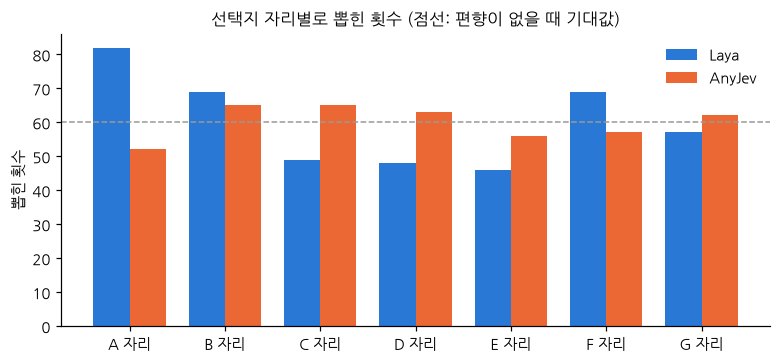

In [5]:
# 자리별로 뽑힌 횟수: 위치 편향이 없으면 자리마다 비슷해야 한다 (60항목 × 7회전 = 420번)
slot_pick = {name: np.bincount([(R[s].argmax() - s) % len(keys) for R in Rs for s in range(len(keys))], minlength=len(keys)) for name, Rs in rot.items()}
fig, ax = plt.subplots(figsize=(7.2, 3.4), dpi=110)
for n, (name, cnt) in enumerate(slot_pick.items()):
    ax.bar(np.arange(len(keys)) + (n - 0.5) * 0.38, cnt, 0.38, label=name, color=["#2a78d6", "#eb6834"][n])
ax.axhline(len(topic), ls="--", lw=1, color="#9a9a96")
ax.set_xticks(range(len(keys)), [f"{chr(65 + s)} 자리" for s in range(len(keys))]); ax.set_ylabel("뽑힌 횟수"); ax.legend(frameon=False)
ax.set_title("선택지 자리별로 뽑힌 횟수 (점선: 편향이 없을 때 기대값)", fontsize=11)
fig.tight_layout(); fig.savefig(OUT / "nb09_position_bias.png", bbox_inches="tight"); plt.show()

## 9.3 지연·비용·데이터 반출

판단 한 건의 지연을 엔진마다 잰다. Jev 는 8장에서 800건을 잰 기록(`results/eval_v1/jev.summary.json`)을 쓴다. 로컬 엔진의 비용은 판단 수에 비례하지 않는다(장비 비용). Jev 는 입력 토큰만큼 과금되고 state 원문이 밖으로 나간다.

In [6]:
TQ = topic[0]["questions"]
lat = {"Laya": [laya_post(it["state"], TQ)["_latency_s"] for it in topic[:30]],
       "AnyJev (7회전)": [anyjev(it["state"], TQ)["_latency_s"] for it in topic[:30]],
       "로컬 LLM (생성, 30건 묶음)": [r["_latency_s"] for r in gen_many([(it["state"], TQ) for it in topic[:30]])]}
jev_sum = json.loads(Path("results/eval_v1/jev.summary.json").read_text(encoding="utf-8"))["report"]["topic"]
state_chars = np.mean([len(json.dumps(i["state"], ensure_ascii=False)) for i in read_jsonl(DATA / "eval_v1.jsonl")])

rows = [{"엔진": name, "지연 중앙값(ms)": 1000 * np.median(v), "판단 100만 건 비용($)": 0.0, "밖으로 나가는 데이터": "없음"} for name, v in lat.items()]
rows.append({"엔진": "Jev (8장 기록)", "지연 중앙값(ms)": jev_sum["latency_p50_ms"],
             "판단 100만 건 비용($)": jev_sum["input_tokens"] / jev_sum["n"] * 0.042,
             "밖으로 나가는 데이터": f"state 원문 평균 {state_chars:.0f}자 + 질문"})
pd.DataFrame(rows)

,엔진,지연 중앙값(ms),판단 100만 건 비용($),밖으로 나가는 데이터
0,Laya,12.906,0.000,없음
1,AnyJev (7회전),125.148,0.000,없음
2,"로컬 LLM (생성, 30건 묶음)",63.691,0.000,없음
3,Jev (8장 기록),178.909,21.218,state 원문 평균 68자 + 질문


로컬 LLM(생성)의 지연은 30건을 한 배치로 생성한 시간을 건수로 나눈 값이다. 한 건씩 보내면 몇 배로 늘어난다. 서빙 엔진 없이 처리량을 내는 방법이 배치다.

## 정리

이 노트북이 잰 것이다. 결과 해석은 9장 본문에서 한다.

- 9.1 같은 러닝 예제에 대한 네 엔진의 답·확률·지연
- 9.2 선택지 순서를 돌렸을 때 답이 바뀌는 비율, 순서 고정과 순환 평균의 정확도, 자리별로 뽑힌 횟수
- 9.3 판단 한 건의 지연, 100만 건 비용, 밖으로 나가는 데이터